# **🏠 Predict House Prices**

---

# Regression Modelling

## Objectives

- Fit and evaluate regression models to predict house `SalePrice`.
- Identify a model that provides suitable predictive performance on unseen data.

## Inputs

- `outputs/datasets/cleaned/TrainSetCleaned.csv`
- `outputs/datasets/cleaned/TestSetCleaned.csv`
- Feature engineering decisions identified in the previous notebook.

## Outputs

- Train set (features and target).
- Test set (features and target).
- ML pipeline to predict house `SalePrice`.
- Feature importance plot.

## Additional Comments

This notebook forms part of the **Modelling and Evaluation** stages of the CRISP-DM process.

---

## ⚙️ 2. Set Up the Notebook

### Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'/workspaces/milestone-project5-heritage-housing-issues/jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chdir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'/workspaces/milestone-project5-heritage-housing-issues'

---

## 📥 3. Load Data

Load the cleaned training and test datasets produced during the data cleaning stage.

In [4]:
import numpy as np
import pandas as pd

TrainSet = pd.read_csv(
    "outputs/datasets/cleaned/TrainSetCleaned.csv"
)

TestSet = pd.read_csv(
    "outputs/datasets/cleaned/TestSetCleaned.csv"
)

print(f"Train Set shape: {TrainSet.shape}")
print(f"Test Set shape: {TestSet.shape}")

Train Set shape: (1168, 21)
Test Set shape: (292, 21)


---

## 🔧 4. Define the ML Pipeline

### Feature Engineering and Modelling Pipeline

A pipeline is created to apply the feature engineering steps identified in the
previous notebook.

Specifically, the pipeline will:

- Encode the categorical features (`OrdinalEncoder` and `OneHotEncoder`)
- Apply numerical transformations (`LogTransformer` and `PowerTransformer`)
- Scale the features (`StandardScaler`)
- Select features using `SelectFromModel`
- Fit a regression model

In [5]:
from sklearn.pipeline import Pipeline

# Feature Engineering
from feature_engine.encoding import OrdinalEncoder, OneHotEncoder
from feature_engine import transformation as vt

# Feature Scaling
from sklearn.preprocessing import StandardScaler

# Feature Selection
from sklearn.feature_selection import SelectFromModel

# ML Algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    AdaBoostRegressor
)
from xgboost import XGBRegressor


def PipelineOptimization(model):
    """
    Creates a regression pipeline using the feature engineering decisions
    identified in the Feature Engineering notebook.
    """
    pipeline_base = Pipeline([

        # CATEGORICAL ENCODING
        ("OrdinalCategoricalEncoder", OrdinalEncoder(
    encoding_method='arbitrary',
    variables=[
        'BsmtExposure',
        'GarageFinish',
        'KitchenQual'
    ],
    unseen='encode'
)),

        ("OneHotCategoricalEncoder", OneHotEncoder(
            variables=['BsmtFinType1'],
            drop_last=False
        )),

        # NUMERICAL TRANSFORMATIONS
        ("LogTransformer", vt.LogTransformer(
            variables=[
                '1stFlrSF',
                'GrLivArea',
                'LotArea',
                'LotFrontage'
            ]
        )),

        ("PowerTransformer", vt.PowerTransformer(
            variables=[
                'BsmtUnfSF',
                'TotalBsmtSF'
            ]
        )),

        # FEATURE SCALING
        ("feat_scaling", StandardScaler()),

        # FEATURE SELECTION
        ("feat_selection", SelectFromModel(model)),

        # MODEL
        ("model", model),

    ])

    return pipeline_base

### Hyperparameter Optimisation Class

The `HyperparameterOptimizationSearch` class is adapted from the Code Institute Predictive Analytics course material.

The class works as follows:

- `__init__` receives the models and their hyperparameters.
- `fit` tests each model and its hyperparameters using `GridSearchCV`.
- `score_summary` summarises the performance of each model.

This allows us to compare the models and identify the best-performing configuration.

In [6]:
from sklearn.model_selection import GridSearchCV


class HyperparameterOptimizationSearch:

    def __init__(self, models, params):
        self.models = models
        self.params = params
        self.keys = models.keys()
        self.grid_searches = {}

    def fit(self, X, y, cv, n_jobs, verbose=1, scoring=None):
        for key in self.keys:
            print(f"\nRunning GridSearchCV for {key} \n")

            model = PipelineOptimization(self.models[key])
            params = self.params[key]

            gs = GridSearchCV(
                model,
                params,
                cv=cv,
                n_jobs=n_jobs,
                verbose=verbose,
                scoring=scoring
            )

            gs.fit(X, y)
            self.grid_searches[key] = gs

    def score_summary(self, sort_by='mean_score'):

        def row(key, scores, params):
            d = {
                'estimator': key,
                'min_score': min(scores),
                'max_score': max(scores),
                'mean_score': np.mean(scores),
                'std_score': np.std(scores),
            }
            return pd.Series({**params, **d})

        rows = []

        for k in self.grid_searches:
            params = self.grid_searches[k].cv_results_['params']
            scores = []

            for i in range(self.grid_searches[k].cv):
                key = "split{}_test_score".format(i)
                r = self.grid_searches[k].cv_results_[key]
                scores.append(r.reshape(len(params), 1))

            all_scores = np.hstack(scores)

            for p, s in zip(params, all_scores):
                rows.append(row(k, s, p))

        df = pd.concat(rows, axis=1).T.sort_values(
            [sort_by], ascending=False
        )

        columns = [
            'estimator',
            'min_score',
            'mean_score',
            'max_score',
            'std_score'
        ]

        columns = columns + [
            c for c in df.columns if c not in columns
        ]

        return df[columns], self.grid_searches

---

## ✂️ 5. Prepare Train and Test Sets

The training and test sets were created during the data cleaning stage to prevent data leakage.

The predictor variables and target variable `SalePrice` are now separated for modelling.

In [7]:
X_train = TrainSet.drop(columns=['SalePrice'])
y_train = TrainSet['SalePrice']

X_test = TestSet.drop(columns=['SalePrice'])
y_test = TestSet['SalePrice']

print(
    "* Train set:", X_train.shape, y_train.shape,
    "\n* Test set:", X_test.shape, y_test.shape
)

* Train set: (1168, 20) (1168,) 
* Test set: (292, 20) (292,)


### Train Set Target Distribution

The distribution of the training target `SalePrice` is inspected before modelling.

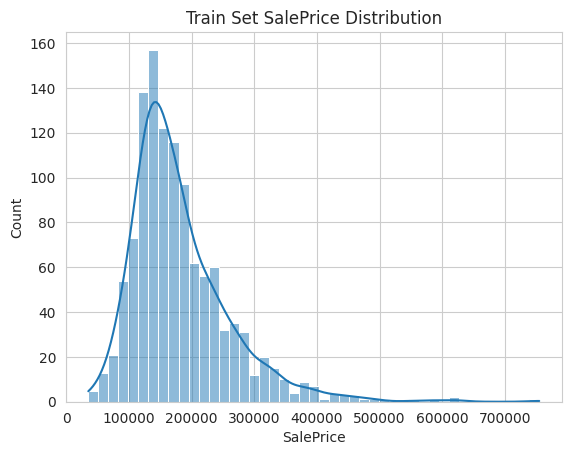

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

sns.histplot(y_train, kde=True)
plt.title("Train Set SalePrice Distribution")
plt.xlabel("SalePrice")
plt.show()

### Target Distribution Interpretation

- `SalePrice` is positively skewed, with most houses priced between roughly 100,000 and 250,000 and fewer houses at the higher end.

- No transformation will currently be applied to `SalePrice` before modelling.

---

## 🔎 6. Quick Model Search

The first step is to compare a range of regression models using their default
hyperparameters.

### Define Models

We now define the regression models to compare, using their default hyperparameters.

In [9]:
models_quick_search = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=0),
    "RandomForestRegressor": RandomForestRegressor(random_state=0),
    "ExtraTreesRegressor": ExtraTreesRegressor(random_state=0),
    "AdaBoostRegressor": AdaBoostRegressor(random_state=0),
    "GradientBoostingRegressor": GradientBoostingRegressor(random_state=0),
    "XGBRegressor": XGBRegressor(random_state=0),
}

params_quick_search = {
    "LinearRegression": {},
    "DecisionTreeRegressor": {},
    "RandomForestRegressor": {},
    "ExtraTreesRegressor": {},
    "AdaBoostRegressor": {},
    "GradientBoostingRegressor": {},
    "XGBRegressor": {},
}

### Model Performance Requirement

The project requirement is to achieve an **R² score of at least 0.75 on both
the training and test sets**.

We now run the quick search using the training data.

The models are compared using their default hyperparameters, with `R²` used to measure performance and 5-fold cross-validation (`cv=5`).

In [10]:
search = HyperparameterOptimizationSearch(
    models=models_quick_search,
    params=params_quick_search
)

search.fit(
    X_train,
    y_train,
    scoring='r2',
    n_jobs=-1,
    cv=5
)


Running GridSearchCV for LinearRegression 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i


Running GridSearchCV for DecisionTreeRegressor 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is 


Running GridSearchCV for RandomForestRegressor 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


...

/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is 


Running GridSearchCV for GradientBoostingRegressor 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is 


Running GridSearchCV for XGBRegressor 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is 

### Quick Search Results

LinearRegression achieved the highest mean cross-validation R² score (0.822), followed by ExtraTreesRegressor (0.814) and RandomForestRegressor (0.804).

LinearRegression and ExtraTreesRegressor were selected for further evaluation.

In [11]:
grid_search_summary, grid_search_pipelines = search.score_summary(
    sort_by='mean_score'
)

grid_search_summary

,estimator,min_score,mean_score,max_score,std_score
0,LinearRegression,0.749738,0.822212,0.862258,0.04274
3,ExtraTreesRegressor,0.667053,0.813753,0.873809,0.074994
2,RandomForestRegressor,0.695521,0.804006,0.852613,0.060153
5,GradientBoostingRegressor,0.61232,0.775373,0.851737,0.090872
4,AdaBoostRegressor,0.679228,0.757187,0.805877,0.04187
6,XGBRegressor,0.516448,0.676509,0.783234,0.105127
1,DecisionTreeRegressor,0.494971,0.607988,0.702554,0.079625


| **Estimator**             | **Min Score** | **Mean Score** | **Max Score** | **Std Score** |
| ------------------------- | ------------: | -------------: | ------------: | ------------: |
| LinearRegression          |         0.750 |          0.822 |         0.862 |         0.043 |
| ExtraTreesRegressor       |         0.667 |          0.814 |         0.874 |         0.075 |
| RandomForestRegressor     |         0.696 |          0.804 |         0.853 |         0.060 |
| GradientBoostingRegressor |         0.612 |          0.775 |         0.852 |         0.091 |
| AdaBoostRegressor         |         0.679 |          0.757 |         0.806 |         0.042 |
| XGBRegressor              |         0.516 |          0.677 |         0.783 |         0.105 |
| DecisionTreeRegressor     |         0.495 |          0.608 |         0.703 |         0.080 |

---

## ⚙️ 7. Hyperparameter Optimisation

Following the quick model search, we now perform a more extensive search on the most suitable models.

The aim is to find the best hyperparameter configuration using `GridSearchCV`.

### Define Models and Hyperparameters

`LinearRegression` and `ExtraTreesRegressor` achieved the strongest
performance during the quick search and are therefore selected for further
optimisation.

The hyperparameter settings are based on the recommendations provided in the Code Institute Predictive Analytics course material.

In [12]:
models_search = {
    "LinearRegression": LinearRegression(),
    "ExtraTreesRegressor": ExtraTreesRegressor(random_state=0),
}

params_search = {
    "LinearRegression": {},

    "ExtraTreesRegressor": {
        "model__n_estimators": [100, 50, 150],
        "model__max_depth": [None, 3, 15],
        "model__min_samples_split": [2, 50],
        "model__min_samples_leaf": [1, 50],
    },
}

### Run Extensive Search

We now run the hyperparameter search using `R²` as the scoring metric and 5-fold cross-validation.

In [13]:
search = HyperparameterOptimizationSearch(
    models=models_search,
    params=params_search
)

search.fit(
    X_train,
    y_train,
    scoring='r2',
    n_jobs=-1,
    cv=5
)

/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i


Running GridSearchCV for LinearRegression 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i


Running GridSearchCV for ExtraTreesRegressor 

Fitting 5 folds for each of 36 candidates, totalling 180 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i

### Hyperparameter Search Results

We summarise the results to identify the best-performing model and hyperparameter configuration.

In [14]:
grid_search_summary, grid_search_pipelines = search.score_summary(
    sort_by='mean_score'
)

grid_search_summary

,estimator,min_score,mean_score,max_score,std_score,model__max_depth,model__min_samples_leaf,model__min_samples_split,model__n_estimators
0,LinearRegression,0.749738,0.822212,0.862258,0.04274,NaN,NaN,NaN,NaN
29,ExtraTreesRegressor,0.776182,0.818244,0.850791,0.034075,15,1,50,50
5,ExtraTreesRegressor,0.776182,0.818177,0.850791,0.034022,None,1,50,50
6,ExtraTreesRegressor,0.774086,0.818137,0.852862,0.035475,None,1,50,150
30,ExtraTreesRegressor,0.774086,0.818123,0.852862,0.035465,15,1,50,150
28,ExtraTreesRegressor,0.773027,0.817405,0.851742,0.035825,15,1,50,100
4,ExtraTreesRegressor,0.773027,0.817365,0.851742,0.035794,None,1,50,100
25,ExtraTreesRegressor,0.675214,0.816424,0.878379,0.072667,15,1,2,100
27,ExtraTreesRegressor,0.672628,0.814981,0.878342,0.073577,15,1,2,150
26,ExtraTreesRegressor,0.674543,0.814822,0.880329,0.072676,15,1,2,50


### Select Best Model and Parameters

Although LinearRegression achieved a slightly higher mean score, ExtraTreesRegressor demonstrated competitive performance and a lower standard deviation across the cross-validation folds. Therefore we will go with ExtraTrees Regressor.

In [15]:
best_model = "ExtraTreesRegressor"
best_model

'ExtraTreesRegressor'

In [16]:
best_parameters = grid_search_pipelines[best_model].best_params_
best_parameters

{'model__max_depth': 15,
 'model__min_samples_leaf': 1,
 'model__min_samples_split': 50,
 'model__n_estimators': 50}

In [17]:
pipeline_reg = grid_search_pipelines[best_model].best_estimator_
pipeline_reg

Pipeline(steps=[('OrdinalCategoricalEncoder',
                 OrdinalEncoder(encoding_method='arbitrary', unseen='encode',
                                variables=['BsmtExposure', 'GarageFinish',
                                           'KitchenQual'])),
                ('OneHotCategoricalEncoder',
                 OneHotEncoder(variables=['BsmtFinType1'])),
                ('LogTransformer',
                 LogTransformer(variables=['1stFlrSF', 'GrLivArea', 'LotArea',
                                           'LotFrontage'])),
                ('PowerTransformer',
                 PowerTransformer(variables=['BsmtUnfSF', 'TotalBsmtSF'])),
                ('feat_scaling', StandardScaler()),
                ('feat_selection',
                 SelectFromModel(estimator=ExtraTreesRegressor(random_state=0))),
                ('model',
                 ExtraTreesRegressor(max_depth=15, min_samples_split=50,
                                     n_estimators=50, random_state=0))])

### Hyperparameter Optimisation Interpretation

LinearRegression achieved the highest mean cross-validation R² score of 0.822, closely followed by ExtraTreesRegressor with 0.818.

The best ExtraTreesRegressor configuration used `max_depth=15`, `min_samples_split=50`, `min_samples_leaf=1` and `n_estimators=50`.

Although LinearRegression achieved a slightly higher mean score, ExtraTreesRegressor had a lower standard deviation across the cross-validation folds.

ExtraTreesRegressor was therefore retained for further feature importance analysis and additional hyperparameter optimisation.

---

## 📊 8. Feature Importance

Next, we will identify the most important features using `feature_importances_`.

/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i

* These are the 7 most important features in descending order. The model was trained on them: 
['OverallQual', 'GrLivArea', 'YearBuilt', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearRemodAdd']


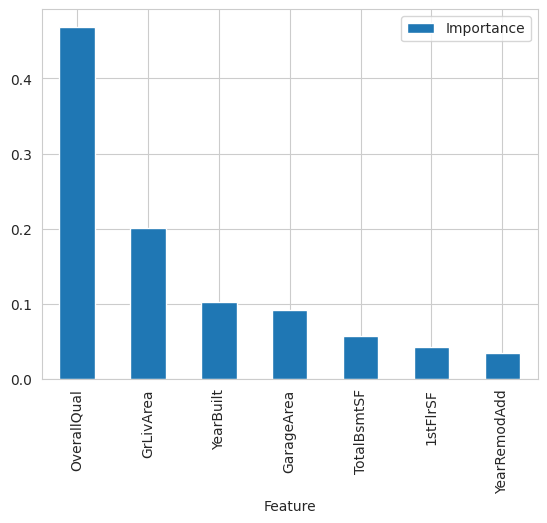

In [18]:
# After feature engineering, the feature space may change.
# Get the column names after the feature engineering steps.

data_cleaning_feat_eng_steps = 4

columns_after_data_cleaning_feat_eng = (
    Pipeline(pipeline_reg.steps[:data_cleaning_feat_eng_steps])
    .transform(X_train)
    .columns
)

# Get the features retained by SelectFromModel
best_features = columns_after_data_cleaning_feat_eng[
    pipeline_reg['feat_selection'].get_support()
].to_list()


# Create DataFrame to display feature importance
df_feature_importance = (
    pd.DataFrame(data={
        'Feature': best_features,
        'Importance': pipeline_reg['model'].feature_importances_
    })
    .sort_values(by='Importance', ascending=False)
)


# Most important features statement and plot
print(
    f"* These are the {len(best_features)} most important features "
    f"in descending order. The model was trained on them: "
    f"\n{df_feature_importance['Feature'].to_list()}"
)

df_feature_importance.plot(
    kind='bar',
    x='Feature',
    y='Importance'
)

plt.show()

### Interpretation of Results

The feature-selection stage selected seven features using `SelectFromModel`:

- `OverallQual`
- `GrLivArea`
- `YearBuilt`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `YearRemodAdd`

`OverallQual` was the most important feature by a considerable margin.


---

## 📈 9. Model Evaluation

The model is evaluated using:

- R² Score
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)

This will be done using our adapted Code Institute function.

In [19]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 
import numpy as np


def regression_performance(X_train, y_train, X_test, y_test, pipeline):
    print("Model Evaluation \n")
    print("* Train Set")
    regression_evaluation(X_train, y_train, pipeline)
    print("* Test Set")
    regression_evaluation(X_test, y_test, pipeline)


def regression_evaluation(X, y, pipeline):
    prediction = pipeline.predict(X)

    print('R2 Score:', r2_score(y, prediction).round(3))  
    print('Mean Absolute Error:', mean_absolute_error(y, prediction).round(3))  
    print('Mean Squared Error:', mean_squared_error(y, prediction).round(3))  
    print('Root Mean Squared Error:',
          np.sqrt(mean_squared_error(y, prediction)).round(3))
    print("\n")


def regression_evaluation_plots(
    X_train, y_train, X_test, y_test, pipeline, alpha_scatter=0.5
):
    pred_train = pipeline.predict(X_train)
    pred_test = pipeline.predict(X_test)

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

    sns.scatterplot(
        x=y_train, y=pred_train,
        alpha=alpha_scatter, ax=axes[0]
    )
    sns.lineplot(x=y_train, y=y_train, color='red', ax=axes[0])
    axes[0].set_xlabel("Actual")
    axes[0].set_ylabel("Predictions")
    axes[0].set_title("Train Set")

    sns.scatterplot(
        x=y_test, y=pred_test,
        alpha=alpha_scatter, ax=axes[1]
    )
    sns.lineplot(x=y_test, y=y_test, color='red', ax=axes[1])
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predictions")
    axes[1].set_title("Test Set")

    plt.show()

### Train and Test Performance

We evaluate the performance of both the train and test set. This is done by comparing the actual sales price to the predicted sales price.

Model Evaluation 

* Train Set
R2 Score: 0.848
Mean Absolute Error: 19080.564
Mean Squared Error: 934180452.295
Root Mean Squared Error: 30564.366


* Test Set
R2 Score: 0.778
Mean Absolute Error: 21176.606
Mean Squared Error: 1531320488.243
Root Mean Squared Error: 39132.09




/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i

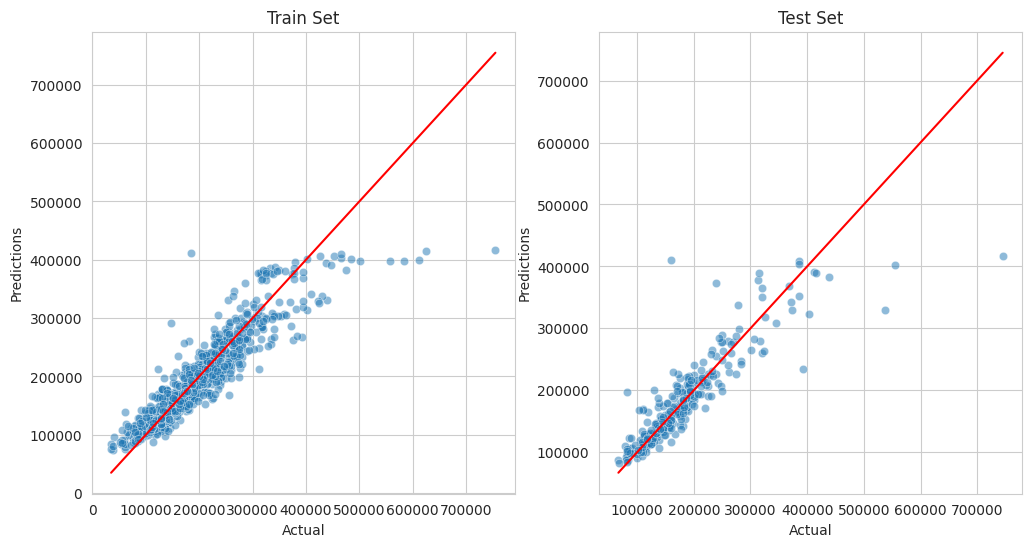

In [20]:
regression_performance(
    X_train, y_train,
    X_test, y_test,
    pipeline_reg
)

regression_evaluation_plots(
    X_train, y_train,
    X_test, y_test,
    pipeline_reg,
    alpha_scatter=0.5
)

### Model Evaluation Interpretation

The table below summarises the performance of the selected ExtraTreesRegressor model on the training and test sets.

| Metric | Train Set | Test Set |
|---|---:|---:|
| R² Score | 0.848 | 0.778 |
| Mean Absolute Error (MAE) | 19,080.564 | 21,176.606 |

- **R²:** The model achieved 0.848 on the training set and 0.778 on the test set, meeting the client's minimum requirement of 0.75.
- **Prediction error:** The average absolute error was approximately 19,081 on the training set and 21,177 on the test set. The higher RMSE indicates some larger prediction errors.
- **Prediction plots:** The model performs better on lower-priced properties but is less accurate for some expensive houses.

### 9.1 Linear Regression Comparison

Just as a quick experiment I want to check what R2 result Linear regression would have achieved. I will run this check because Linear Regression achieved the highest mean cross-validation R² score (0.822) during the initial model search.

In [21]:
# Retrieve the optimised LinearRegression pipeline from Section 7
linear_pipeline = grid_search_pipelines[
    "LinearRegression"
].best_estimator_

# Evaluate on the original full-feature datasets
regression_performance(
    TrainSet.drop(columns=['SalePrice']),
    y_train,
    TestSet.drop(columns=['SalePrice']),
    y_test,
    linear_pipeline
)

Model Evaluation 

* Train Set
R2 Score: 0.835
Mean Absolute Error: 20669.141
Mean Squared Error: 1015150123.828
Root Mean Squared Error: 31861.421


* Test Set
R2 Score: 0.688
Mean Absolute Error: 24662.777
Mean Squared Error: 2153847850.069
Root Mean Squared Error: 46409.566




/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i

#### Linear Regression — Evaluation

LinearRegression was evaluated using the same training and test datasets as the original model.

| Metric | Train Set | Test Set |
|---|---:|---:|
| R² Score | 0.835 | 0.688 |
| Mean Absolute Error (MAE) | $20,669 | $24,663 |
| Root Mean Squared Error (RMSE) | $31,861 | $46,410 |

Linear regression achieved the client´s minimum requirement on the train dataset but did not meet the client minimum requirement on the test set.

**Decision:** Do not retain LinearRegression for further optimisation. Continue with ExtraTreesRegressor, which met the client's minimum R² requirement on both datasets.

---

## 🧪 10. Further Model Experiments

We have already met the client's minimum requirement of an R² score of at least 0.75 on both the training and test sets. However, the model's performance could potentially be improved. We will run two experiments to investigate this.

- **SmartCorrelatedSelection:** Test an alternative feature selection method.
- **Additional Hyperparameter Optimisation:** Explore different hyperparameter values to improve model performance.

The results will be compared with the original model to determine which approach should be used for the final pipeline.

### 10.1 SmartCorrelatedSelection Experiment

SelectFromModel was replaced with SmartCorrelatedSelection to investigate whether this improves predictive performance.

The same ExtraTreesRegressor hyperparameters are used to evaluate the alternative approach.

In [22]:
# Use the full cleaned datasets for this experiment
X_train_smart = TrainSet.drop(columns=['SalePrice'])
X_test_smart = TestSet.drop(columns=['SalePrice'])

print("Train shape:", X_train_smart.shape)
print("Test shape:", X_test_smart.shape)

Train shape: (1168, 20)
Test shape: (292, 20)


In [23]:
from feature_engine.selection import SmartCorrelatedSelection

def PipelineSmartCorrelation(model):

    pipeline = Pipeline([

        # CATEGORICAL ENCODING
        ("OrdinalCategoricalEncoder", OrdinalEncoder(
            encoding_method='arbitrary',
            variables=[
                'BsmtExposure',
                'GarageFinish',
                'KitchenQual'
            ],
            unseen='encode'
        )),

        ("OneHotCategoricalEncoder", OneHotEncoder(
            variables=['BsmtFinType1'],
            drop_last=False
        )),

        # NUMERICAL TRANSFORMATIONS
        ("LogTransformer", vt.LogTransformer(
            variables=[
                '1stFlrSF',
                'GrLivArea',
                'LotArea',
                'LotFrontage'
            ]
        )),

        ("PowerTransformer", vt.PowerTransformer(
            variables=[
                'BsmtUnfSF',
                'TotalBsmtSF'
            ]
        )),

        # CORRELATED FEATURE SELECTION
        ("feat_selection", SmartCorrelatedSelection(
            variables=None,
            method='spearman',
            threshold=0.6,
            selection_method='variance'
        )),

        # FEATURE SCALING
        ("feat_scaling", StandardScaler()),

        # MODEL
        ("model", model)

    ])

    return pipeline

In [24]:
# Create the experimental pipeline
smart_corr_pipeline = PipelineSmartCorrelation(
    ExtraTreesRegressor(
        max_depth=15,
        min_samples_split=50,
        min_samples_leaf=1,
        n_estimators=50,
        random_state=0
    )
)

# Fit the experimental model
smart_corr_pipeline.fit(X_train_smart, y_train)

# Evaluate model performance
regression_performance(
    X_train_smart,
    y_train,
    X_test_smart,
    y_test,
    smart_corr_pipeline
)

/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i

Model Evaluation 

* Train Set
R2 Score: 0.849
Mean Absolute Error: 19084.934
Mean Squared Error: 928003827.298
Root Mean Squared Error: 30463.155


* Test Set
R2 Score: 0.759
Mean Absolute Error: 22782.232
Mean Squared Error: 1665774159.241
Root Mean Squared Error: 40813.897





#### SmartCorrelatedSelection — Evaluation

The experimental pipeline was evaluated using the same training and test datasets as the original model.

| Metric | Existing Model | SmartCorrelatedSelection |
|---|---:|---:|
| Train R² | 0.848 | 0.849 |
| Test R² | 0.778 | 0.759 |
| Test MAE | $21,177 | $22,782 |

Although the experimental model met the client's minimum R² requirement of 0.75 on both datasets, it did not improve performance on unseen data.

Test R² decreased from 0.778 to 0.759, while test MAE increased from approximately $21,177 to $22,782.

**Decision:** Retain `SelectFromModel` rather than `SmartCorrelatedSelection` in the final pipeline.


### 10.2 Additional Hyperparameter Optimisation

An extended GridSearchCV was performed on `ExtraTreesRegressor` using six hyperparameters, each with three values.

| Hyperparameter | Values | Rationale |
|---|---|---|
| `n_estimators` | 50, 100, 150 | Number of trees |
| `max_depth` | 10, 20, None | Control tree depth |
| `min_samples_split` | 5, 10, 20 | Control splitting |
| `min_samples_leaf` | 1, 2, 4 | Control leaf size |
| `max_features` | 0.6, 0.8, 1.0 | Control features per split |
| `min_impurity_decrease` | 0.0, 0.01, 0.1 | Control minimum split improvement |

Three grouped grids were used to limit processing time to 135 fits. Five-fold cross-validation was used to select the best model.

#### Test Different Hyperparameters

In [25]:
models_tuning = {
    "ExtraTreesRegressor": ExtraTreesRegressor(random_state=0),
}

params_tuning = {
    "ExtraTreesRegressor": [
        {
            "model__n_estimators": [50, 100, 150],
            "model__max_depth": [10, 20, None],
            "model__min_samples_split": [5],
            "model__min_samples_leaf": [4],
            "model__max_features": [1.0],
            "model__min_impurity_decrease": [0.0],
        },
        {
            "model__n_estimators": [100],
            "model__max_depth": [None],
            "model__min_samples_split": [5, 10, 20],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": [1.0],
            "model__min_impurity_decrease": [0.0],
        },
        {
            "model__n_estimators": [100],
            "model__max_depth": [None],
            "model__min_samples_split": [5],
            "model__min_samples_leaf": [4],
            "model__max_features": [0.6, 0.8, 1.0],
            "model__min_impurity_decrease": [0.0, 0.01, 0.1],
        },
    ],
}

#### Run Extensive Search

In [26]:
# Use full feature sets for this experiment
X_train_tuning = TrainSet.drop(columns=["SalePrice"])
X_test_tuning = TestSet.drop(columns=["SalePrice"])

# Create an independent search
tuning_search = HyperparameterOptimizationSearch(
    models=models_tuning,
    params=params_tuning
)

# Fit using training data only
tuning_search.fit(
    X_train_tuning,
    y_train,
    scoring="r2",
    n_jobs=-1,
    cv=5
)


Running GridSearchCV for ExtraTreesRegressor 

Fitting 5 folds for each of 27 candidates, totalling 135 fits


/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is 

In [27]:
tuning_summary, tuning_pipelines = tuning_search.score_summary(
    sort_by="mean_score"
)

tuning_summary

,estimator,min_score,mean_score,max_score,std_score,model__max_depth,model__max_features,model__min_impurity_decrease,model__min_samples_leaf,model__min_samples_split,model__n_estimators
3,ExtraTreesRegressor,0.791931,0.840642,0.874126,0.035598,20,1.0,0.0,4,5,50
6,ExtraTreesRegressor,0.791931,0.840642,0.874126,0.035598,None,1.0,0.0,4,5,50
15,ExtraTreesRegressor,0.784597,0.840132,0.874511,0.037927,None,1.0,0.0,4,5,100
25,ExtraTreesRegressor,0.784597,0.840132,0.874511,0.037927,None,1.0,0.01,4,5,100
4,ExtraTreesRegressor,0.784597,0.840132,0.874511,0.037927,20,1.0,0.0,4,5,100
7,ExtraTreesRegressor,0.784597,0.840132,0.874511,0.037927,None,1.0,0.0,4,5,100
24,ExtraTreesRegressor,0.784597,0.840132,0.874511,0.037927,None,1.0,0.0,4,5,100
26,ExtraTreesRegressor,0.783872,0.839986,0.874511,0.03814,None,1.0,0.1,4,5,100
5,ExtraTreesRegressor,0.782,0.839885,0.875315,0.038973,20,1.0,0.0,4,5,150
8,ExtraTreesRegressor,0.782,0.839885,0.875315,0.038973,None,1.0,0.0,4,5,150


In [28]:
tuned_model = tuning_summary.iloc[0, 0]
tuned_model

'ExtraTreesRegressor'

In [29]:
tuned_parameters = tuning_pipelines[tuned_model].best_params_
tuned_parameters

{'model__max_depth': 20,
 'model__max_features': 1.0,
 'model__min_impurity_decrease': 0.0,
 'model__min_samples_leaf': 4,
 'model__min_samples_split': 5,
 'model__n_estimators': 50}

The additional hyperparameter search identified the following best configuration for `ExtraTreesRegressor`:

- `n_estimators`: 50
- `max_depth`: 20 (maximum tree depth)
- `min_samples_split`: 5
- `min_samples_leaf`: 4
- `max_features`: 1.0 (all features considered at each split)
- `min_impurity_decrease`: 0.0 (no minimum impurity reduction required)

These parameters were selected based on the highest mean cross-validation R² score.

In [30]:
tuned_pipeline = tuning_pipelines[tuned_model].best_estimator_
tuned_pipeline

Pipeline(steps=[('OrdinalCategoricalEncoder',
                 OrdinalEncoder(encoding_method='arbitrary', unseen='encode',
                                variables=['BsmtExposure', 'GarageFinish',
                                           'KitchenQual'])),
                ('OneHotCategoricalEncoder',
                 OneHotEncoder(variables=['BsmtFinType1'])),
                ('LogTransformer',
                 LogTransformer(variables=['1stFlrSF', 'GrLivArea', 'LotArea',
                                           'LotFrontage'])),
                ('PowerTransformer',
                 PowerTransformer(variables=['BsmtUnfSF', 'TotalBsmtSF'])),
                ('feat_scaling', StandardScaler()),
                ('feat_selection',
                 SelectFromModel(estimator=ExtraTreesRegressor(random_state=0))),
                ('model',
                 ExtraTreesRegressor(max_depth=20, min_samples_leaf=4,
                                     min_samples_split=5, n_estimators=50,
                                     random_state=0))])

Model Evaluation 

* Train Set
R2 Score: 0.912
Mean Absolute Error: 14359.638
Mean Squared Error: 539987488.702
Root Mean Squared Error: 23237.631


* Test Set
R2 Score: 0.808
Mean Absolute Error: 20214.55
Mean Squared Error: 1325960349.548
Root Mean Squared Error: 36413.738




/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:223: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(X[feature]):
/home/cistudent/.local/lib/python3.12/site-packages/feature_engine/encoding/base_encoder.py:230: FutureWarning: The 'downcast' keyword i

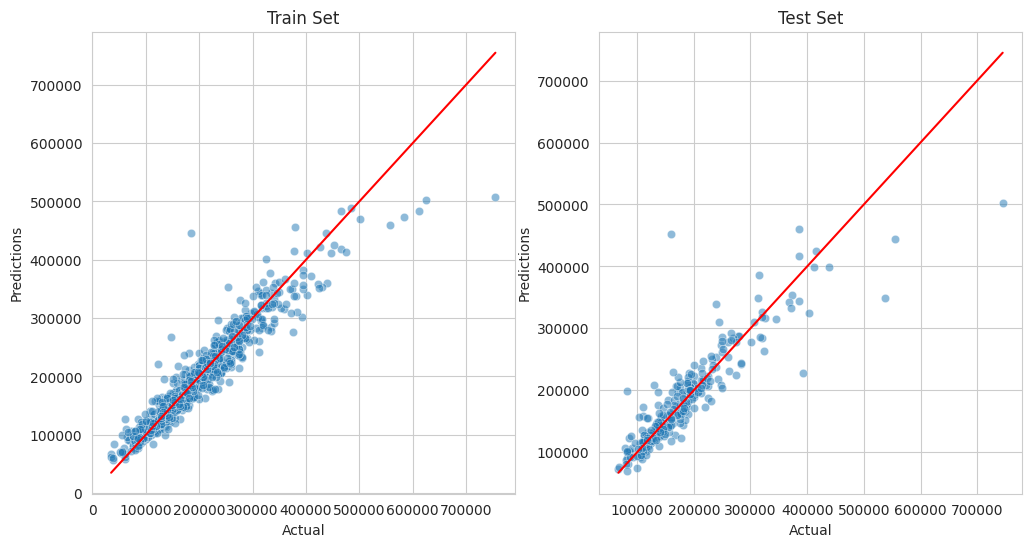

In [31]:
regression_performance(
    X_train_tuning,
    y_train,
    X_test_tuning,
    y_test,
    tuned_pipeline
)

regression_evaluation_plots(
    X_train_tuning,
    y_train,
    X_test_tuning,
    y_test,
    tuned_pipeline,
    alpha_scatter=0.5
)


#### Original vs Tuned ExtraTreesRegressor

| Metric | Original Train | Original Test | Tuned Train | Tuned Test |
|---|---:|---:|---:|---:|
| R² Score | 0.848 | 0.778 | 0.912 | 0.808 |
| Mean Absolute Error (MAE) | 19,080.564 | 21,176.606 | 14,359.638 | 20,214.550 |

The additional hyperparameter optimisation improved the test R² score from 0.778 to 0.808 and reduced the test MAE from approximately $21,177 to $20,215.

Both training and test R² scores exceed the client's minimum requirement of 0.75. 

**Decision:** Retain the optimised ExtraTreesRegressor for the final regression pipeline with the optimised hyperparameters.

---

## 🔁 11. Refit with the Most Important Features

From our previous analyses, we have selected ExtraTreesRegressor, optimised its hyperparameters, and identified the seven most important features.

| Component | Selected result |
|---|---|
| **Selected algorithm** | `ExtraTreesRegressor` |
| **Optimised hyperparameters (Section 10)** | `n_estimators=50`, `max_depth=20`, `min_samples_split=5`, `min_samples_leaf=4`, `max_features=1.0`, `min_impurity_decrease=0.0` |
| **Selected features (Section 8)** | `OverallQual`, `GrLivArea`, `YearBuilt`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`, `YearRemodAdd` |

We will refit the pipeline using these seven features and the optimised hyperparameters.

### Prepare Train and Test Sets

The training and test sets were already created during the data cleaning stage.

We now prepare the original predictor and target variables before filtering to the most important features.

In [32]:
X_train = TrainSet.drop(columns=['SalePrice'])
y_train = TrainSet['SalePrice']

X_test = TestSet.drop(columns=['SalePrice'])
y_test = TestSet['SalePrice']

print(
    "* Train set:", X_train.shape, y_train.shape,
    "\n* Test set:", X_test.shape, y_test.shape
)

* Train set: (1168, 20) (1168,) 
* Test set: (292, 20) (292,)


### Filter to Selected Features

Now we subset the best features.

In [33]:
X_train = TrainSet[best_features].copy()
X_test = TestSet[best_features].copy()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Selected features:", best_features)

Train shape: (1168, 7)
Test shape: (292, 7)
Selected features: ['1stFlrSF', 'GarageArea', 'GrLivArea', 'OverallQual', 'TotalBsmtSF', 'YearBuilt', 'YearRemodAdd']



### Define the Simplified Pipeline

**Original Pipeline**

`20 Features` → `Feature Engineering` → `Scaling` → `Feature Selection` → `7 Features` → `Model`

**Refitted Pipeline**

`7 Features` → `Feature Engineering` → `Scaling` → `Model`

- Categorical encoders were removed because none of the seven selected features are categorical.
- `SelectFromModel` was removed because the training and test datasets have already been filtered to the seven selected features.
- `ExtraTreesRegressor` will be refitted using the optimised hyperparameters identified in Section 10.

In [34]:
from sklearn.pipeline import Pipeline

# Feature Engineering
from feature_engine import transformation as vt

# Feature Scaling
from sklearn.preprocessing import StandardScaler

# ML Algorithm
from sklearn.ensemble import ExtraTreesRegressor


def PipelineFinalRegression(model):
    """
    Creates the final regression pipeline using only the
    seven most important features.
    """

    pipeline_base = Pipeline([

        # NUMERICAL TRANSFORMATIONS
        ("LogTransformer", vt.LogTransformer(
            variables=[
                '1stFlrSF',
                'GrLivArea'
            ]
        )),

        ("PowerTransformer", vt.PowerTransformer(
            variables=['TotalBsmtSF']
        )),

        # FEATURE SCALING
        ("feat_scaling", StandardScaler()),

        # MODEL
        ("model", model),

    ])

    return pipeline_base

### Refit the Best Model

We now refit ExtraTreesRegressor using the optimised hyperparameters identified in Section 10 and the seven selected features.

In [35]:
best_pipeline = PipelineFinalRegression(
    ExtraTreesRegressor(
        n_estimators=50,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=4,
        max_features=1.0,
        min_impurity_decrease=0.0,
        random_state=0
    )
)

best_pipeline.fit(X_train, y_train)

best_pipeline

Pipeline(steps=[('LogTransformer',
                 LogTransformer(variables=['1stFlrSF', 'GrLivArea'])),
                ('PowerTransformer',
                 PowerTransformer(variables=['TotalBsmtSF'])),
                ('feat_scaling', StandardScaler()),
                ('model',
                 ExtraTreesRegressor(max_depth=20, min_samples_leaf=4,
                                     min_samples_split=5, n_estimators=50,
                                     random_state=0))])

### Evaluate the Refitted Model

Finally, we evaluate the refitted pipeline to confirm that using only the selected features has not reduced model performance.

Model Evaluation 

* Train Set
R2 Score: 0.912
Mean Absolute Error: 14359.638
Mean Squared Error: 539987488.702
Root Mean Squared Error: 23237.631


* Test Set
R2 Score: 0.808
Mean Absolute Error: 20214.55
Mean Squared Error: 1325960349.548
Root Mean Squared Error: 36413.738




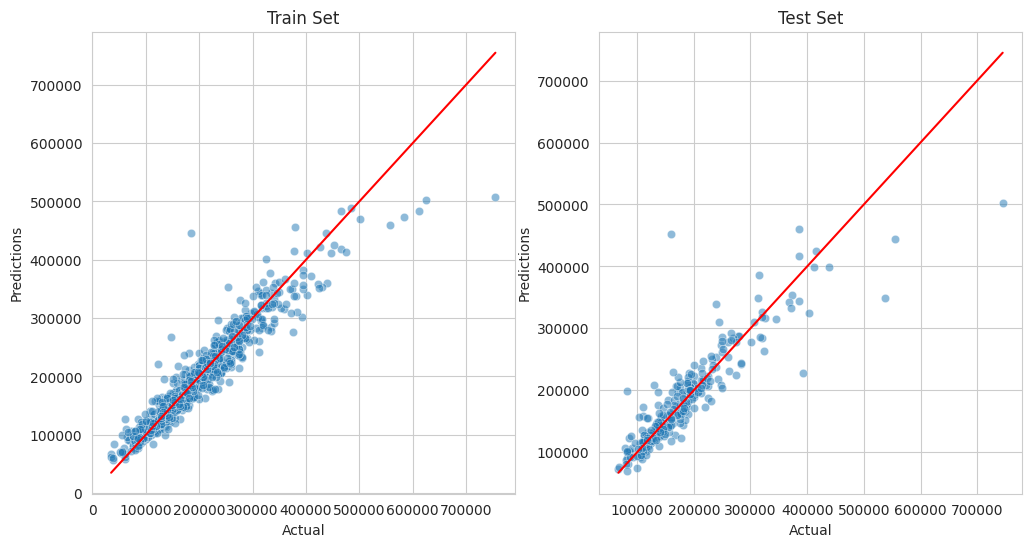

In [36]:
regression_performance(
    X_train,
    y_train,
    X_test,
    y_test,
    best_pipeline
)

regression_evaluation_plots(
    X_train,
    y_train,
    X_test,
    y_test,
    best_pipeline,
    alpha_scatter=0.5
)

### Refit Results

- The model was refitted using the seven features identified during feature importance.
- The feature selection stage was removed as the seven features are supplied directly to the model.
- The optimised hyperparameters from Section 10 were retained.
- The refitted model achieved an R² score of **0.912 on the training set** and **0.808 on the test set**, exceeding the client requirement of 0.75.
- These results match Section 10, confirming that simplifying the pipeline did not reduce model performance.

---

## 💾 12. Save Final Model and Outputs

The following will now be saved:
- Train set
- Test set
- Final regression pipeline
- Feature importance plot

In [37]:
import joblib
import os

version = 'v1'
file_path = f'outputs/ml_pipeline/predict_house_prices/{version}'

try:
    os.makedirs(name=file_path)
except Exception as e:
    print(e)

[Errno 17] File exists: 'outputs/ml_pipeline/predict_house_prices/v1'


### Train Set: features and target

Save the final train set.

In [38]:
X_train.head()

,1stFlrSF,GarageArea,GrLivArea,OverallQual,TotalBsmtSF,YearBuilt,YearRemodAdd
0,1828,774,1828,9,1822,2007,2007
1,894,308,894,5,894,1962,1962
2,964,432,964,5,876,1921,2006
3,1689,857,1689,8,1568,2002,2002
4,1541,843,1541,7,1541,2001,2002


In [39]:
X_train.to_csv(f"{file_path}/X_train.csv", index=False)

In [40]:
y_train

0       314813
1       109500
2       163500
3       271000
4       205000
         ...  
1163    337000
1164    128000
1165    112000
1166    234000
1167    221000
Name: SalePrice, Length: 1168, dtype: int64

In [41]:
y_train.to_csv(f"{file_path}/y_train.csv", index=False)

### Test Set: features and target

Save the final test set.

In [42]:
X_test.head()

,1stFlrSF,GarageArea,GrLivArea,OverallQual,TotalBsmtSF,YearBuilt,YearRemodAdd
0,2515,484,2515,6,2035,1957,1975
1,958,240,1578,6,806,1941,1950
2,979,352,1203,5,709,1950,1950
3,1156,505,2022,7,1160,1977,1977
4,525,264,1092,6,525,1971,1971


In [43]:
X_test.to_csv(f"{file_path}/X_test.csv", index=False)

In [44]:
y_test

0      200624
1      133000
2      110000
3      192000
4       88000
        ...  
287    324000
288    555000
289    136000
290     82500
291    101000
Name: SalePrice, Length: 292, dtype: int64

In [45]:
y_test.to_csv(f"{file_path}/y_test.csv", index=False)

### Modelling Pipeline

ML pipeline for predicting house sale prices.

In [46]:
best_pipeline

Pipeline(steps=[('LogTransformer',
                 LogTransformer(variables=['1stFlrSF', 'GrLivArea'])),
                ('PowerTransformer',
                 PowerTransformer(variables=['TotalBsmtSF'])),
                ('feat_scaling', StandardScaler()),
                ('model',
                 ExtraTreesRegressor(max_depth=20, min_samples_leaf=4,
                                     min_samples_split=5, n_estimators=50,
                                     random_state=0))])

In [47]:
joblib.dump(
    value=best_pipeline,
    filename=f"{file_path}/reg_pipeline.pkl"
)

['outputs/ml_pipeline/predict_house_prices/v1/reg_pipeline.pkl']

### Feature Importance Plot

Save the feature importance plot for use in the dashboard.

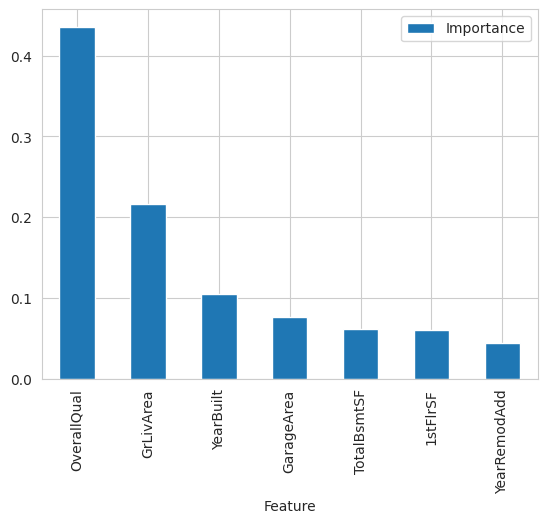

In [48]:
df_final_feature_importance = (
    pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': best_pipeline['model'].feature_importances_
    })
    .sort_values(by='Importance', ascending=False)
)

df_final_feature_importance.plot(
    kind='bar',
    x='Feature',
    y='Importance'
)

plt.savefig(
    f'{file_path}/features_importance.png',
    bbox_inches='tight'
)

plt.show()

---